# EDA and Correlation Analysis
Employee Attrition Risk Analyzer

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
BLUE = "#1F3A5F"

df = pd.read_csv("../data/processed/cleaned_data.csv")
df_model = pd.read_csv("../data/processed/model_ready_data.csv")

df["Attr"] = (df["Attrition"] == "Yes").astype(int)
print("Overall attrition rate: {:.2f}%".format(df["Attr"].mean() * 100))

Overall attrition rate: 16.12%


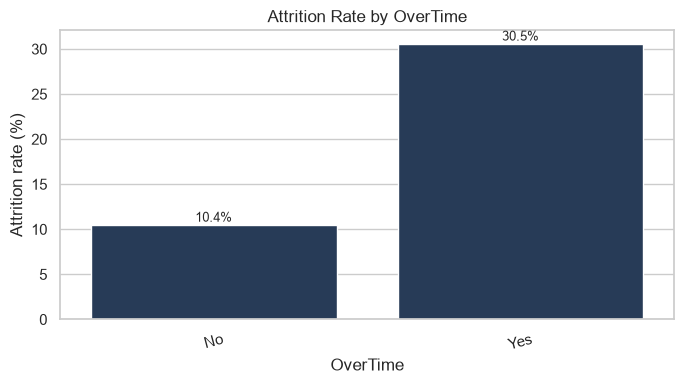

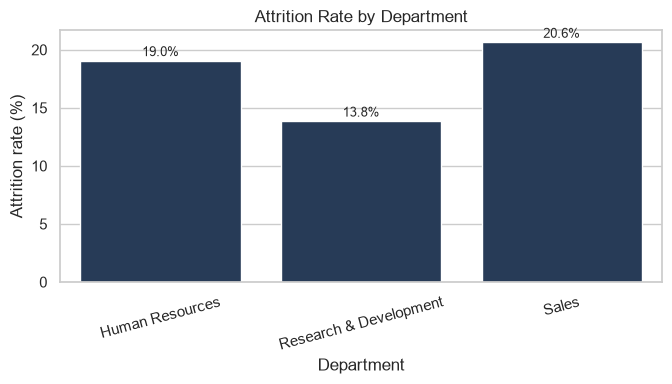

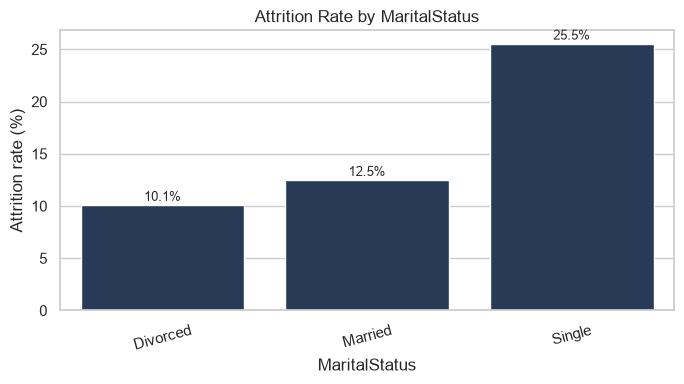

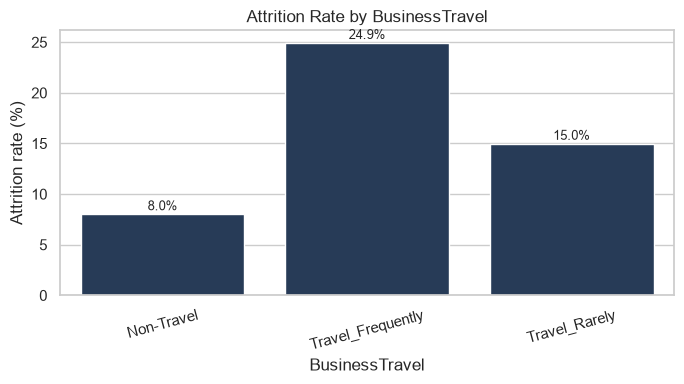

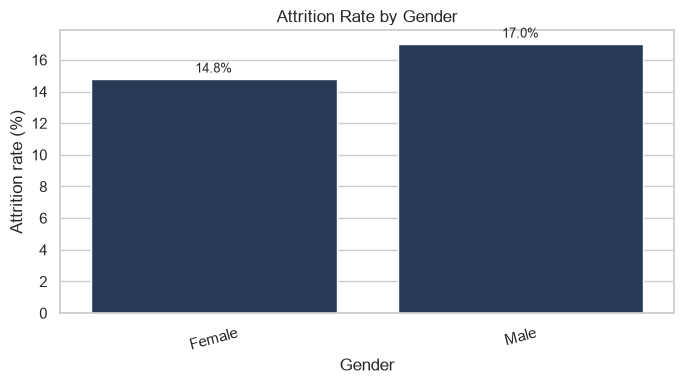

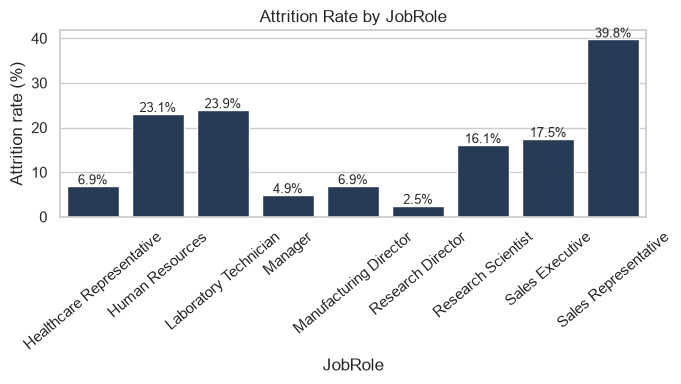

JobRole
Healthcare Representative     6.870229
Human Resources              23.076923
Laboratory Technician        23.938224
Manager                       4.901961
Manufacturing Director        6.896552
Research Director             2.500000
Research Scientist           16.095890
Sales Executive              17.484663
Sales Representative         39.759036
Name: Attr, dtype: float64

In [2]:
def rate_plot(data, col, title=None, rotate=0):
    r = data.groupby(col, observed=True)["Attr"].mean().mul(100)
    plt.figure(figsize=(7, 4))
    ax = sns.barplot(x=r.index.astype(str), y=r.values, color=BLUE)
    for i, v in enumerate(r.values):
        ax.text(i, v + 0.4, f"{v:.1f}%", ha="center", fontsize=9)
    plt.ylabel("Attrition rate (%)")
    plt.xlabel(col)
    plt.title(title or f"Attrition Rate by {col}")
    plt.xticks(rotation=rotate)
    plt.tight_layout()
    plt.savefig(f"../outputs/charts/03_attrition_by_{col}.png", dpi=300)
    plt.show()
    return r

for col in ["OverTime", "Department", "MaritalStatus", "BusinessTravel", "Gender"]:
    rate_plot(df, col, rotate=15)

rate_plot(df, "JobRole", rotate=40)

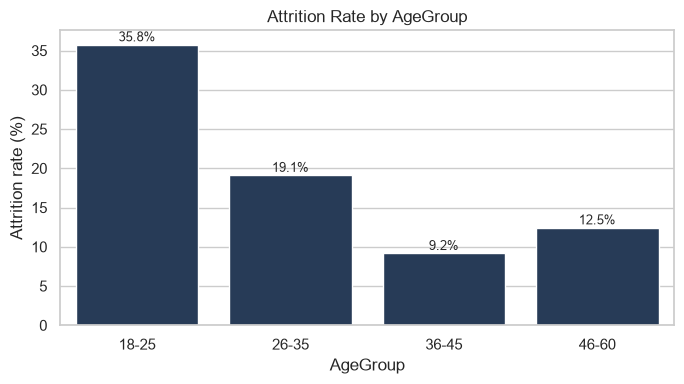

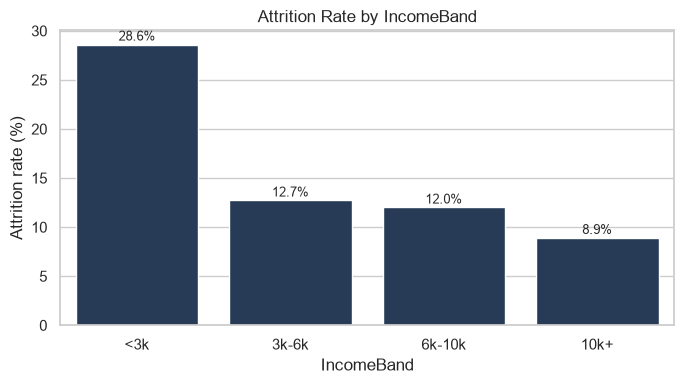

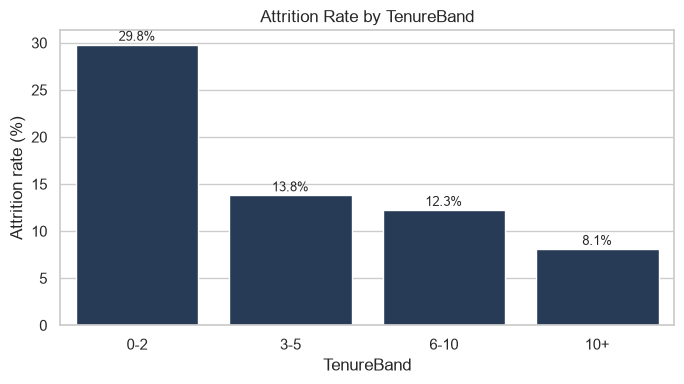

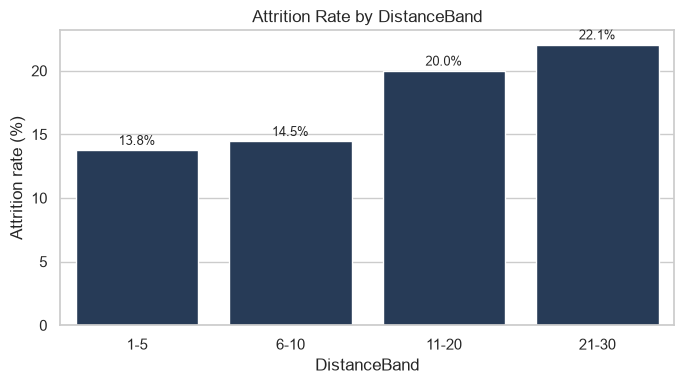

In [3]:
df["AgeGroup"] = pd.cut(df["Age"], [17, 25, 35, 45, 60],
                        labels=["18-25", "26-35", "36-45", "46-60"])
df["IncomeBand"] = pd.cut(df["MonthlyIncome"], [0, 3000, 6000, 10000, 20000],
                          labels=["<3k", "3k-6k", "6k-10k", "10k+"])
df["TenureBand"] = pd.cut(df["YearsAtCompany"], [-1, 2, 5, 10, 50],
                          labels=["0-2", "3-5", "6-10", "10+"])
df["DistanceBand"] = pd.cut(df["DistanceFromHome"], [0, 5, 10, 20, 30],
                            labels=["1-5", "6-10", "11-20", "21-30"])

for col in ["AgeGroup", "IncomeBand", "TenureBand", "DistanceBand"]:
    rate_plot(df, col)

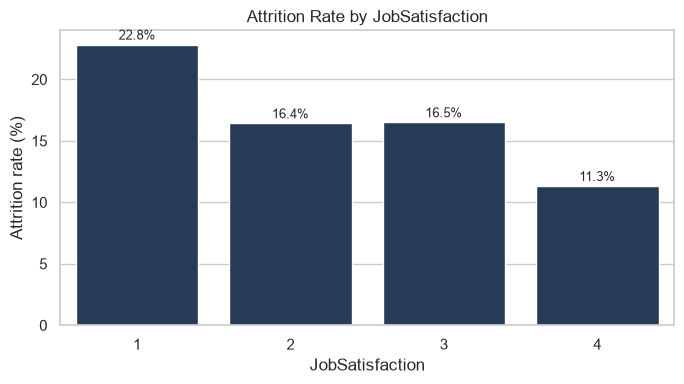

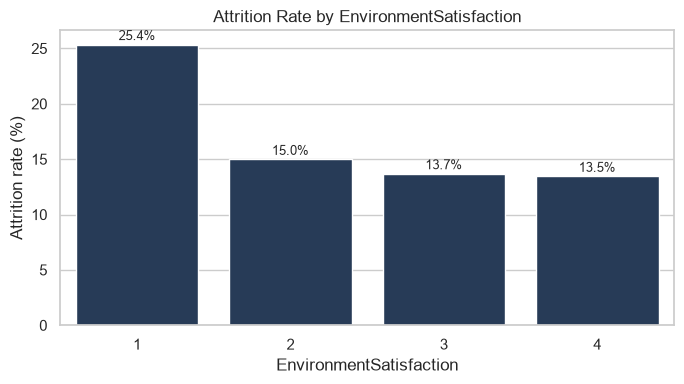

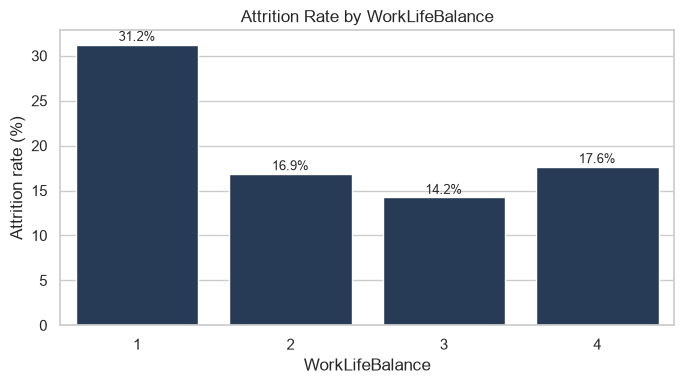

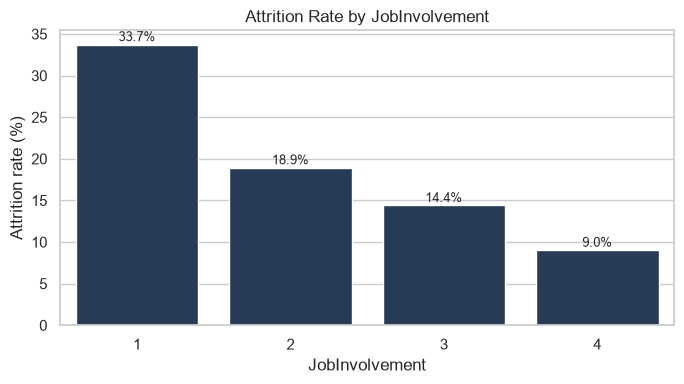

In [4]:
for col in ["JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance", "JobInvolvement"]:
    rate_plot(df, col)

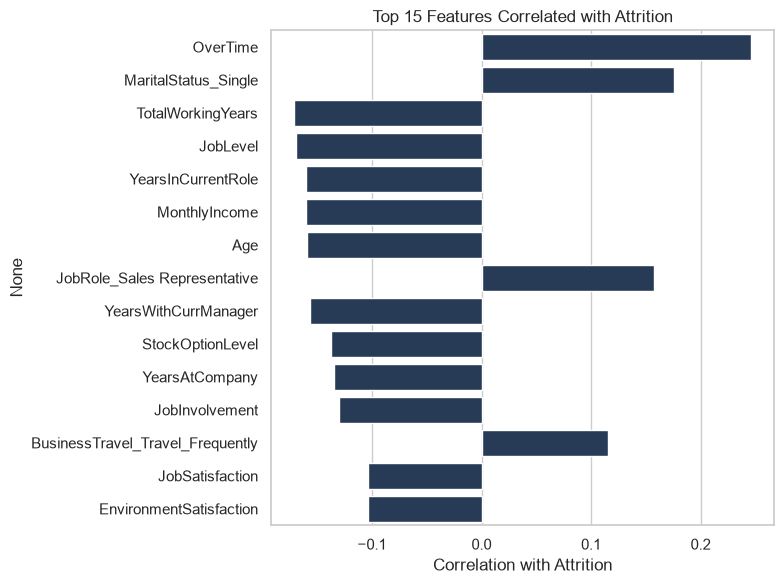

OverTime                            0.246118
MaritalStatus_Single                0.175419
TotalWorkingYears                  -0.171063
JobLevel                           -0.169105
YearsInCurrentRole                 -0.160545
MonthlyIncome                      -0.159840
Age                                -0.159205
JobRole_Sales Representative        0.157234
YearsWithCurrManager               -0.156199
StockOptionLevel                   -0.137145
YearsAtCompany                     -0.134392
JobInvolvement                     -0.130016
BusinessTravel_Travel_Frequently    0.115143
JobSatisfaction                    -0.103481
EnvironmentSatisfaction            -0.103369
Name: Attrition, dtype: float64

In [5]:
corr = df_model.corr()["Attrition"].drop("Attrition")
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index, color=BLUE)
plt.title("Top 15 Features Correlated with Attrition")
plt.xlabel("Correlation with Attrition")
plt.tight_layout()
plt.savefig("../outputs/charts/03_top_correlations.png", dpi=300)
plt.show()
top

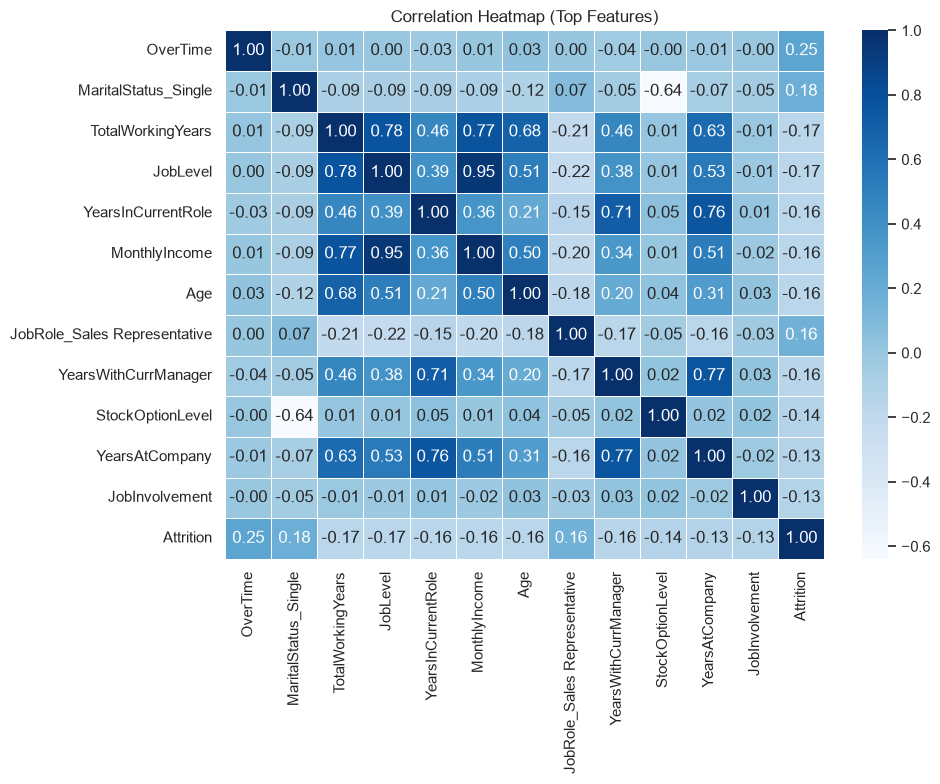

In [6]:
cols = top.head(12).index.tolist() + ["Attrition"]
plt.figure(figsize=(10, 8))
sns.heatmap(df_model[cols].corr(), annot=True, fmt=".2f", cmap="Blues", linewidths=0.5)
plt.title("Correlation Heatmap (Top Features)")
plt.tight_layout()
plt.savefig("../outputs/charts/03_correlation_heatmap.png", dpi=300)
plt.show()

In [7]:
rows = []
for col in ["OverTime", "Department", "MaritalStatus", "BusinessTravel",
            "JobRole", "AgeGroup", "IncomeBand", "TenureBand"]:
    r = df.groupby(col, observed=True)["Attr"].mean().mul(100)
    rows.append({"Factor": col,
                 "Highest Attrition Group": str(r.idxmax()),
                 "Highest Rate %": round(r.max(), 1),
                 "Lowest Attrition Group": str(r.idxmin()),
                 "Lowest Rate %": round(r.min(), 1)})
insights = pd.DataFrame(rows)
insights.to_csv("../outputs/tables/eda_insights.csv", index=False)
insights

,Factor,Highest Attrition Group,Highest Rate %,Lowest Attrition Group,Lowest Rate %
0,OverTime,Yes,30.5,No,10.4
1,Department,Sales,20.6,Research & Development,13.8
2,MaritalStatus,Single,25.5,Divorced,10.1
3,BusinessTravel,Travel_Frequently,24.9,Non-Travel,8.0
4,JobRole,Sales Representative,39.8,Research Director,2.5
5,AgeGroup,18-25,35.8,36-45,9.2
6,IncomeBand,<3k,28.6,10k+,8.9
7,TenureBand,0-2,29.8,10+,8.1


In [8]:
from IPython.display import Markdown, display

def rates(col):
    return df.groupby(col, observed=True)["Attr"].mean().mul(100)

lines = []
overall = df["Attr"].mean() * 100
n_yes = int(df["Attr"].sum())
lines.append(f"1. **Overall attrition:** {n_yes} of {len(df)} employees ({overall:.1f}%) left the company, so the dataset is imbalanced and recall/F1 must be tracked along with accuracy.")

r = rates("OverTime")
lines.append(f"2. **OverTime:** employees working overtime show {r['Yes']:.1f}% attrition versus {r['No']:.1f}% for others, which is {r['Yes']/r['No']:.1f} times higher.")

r = rates("MaritalStatus")
lines.append(f"3. **Marital status:** {r.idxmax()} employees have the highest attrition ({r.max():.1f}%), while {r.idxmin()} employees have the lowest ({r.min():.1f}%).")

r = rates("BusinessTravel")
lines.append(f"4. **Business travel:** the {r.idxmax()} group has the highest attrition ({r.max():.1f}%) and the {r.idxmin()} group the lowest ({r.min():.1f}%).")

r = rates("Department")
lines.append(f"5. **Department:** {r.idxmax()} has the highest attrition ({r.max():.1f}%) and {r.idxmin()} the lowest ({r.min():.1f}%).")

r = rates("JobRole")
lines.append(f"6. **Job role:** {r.idxmax()} has the highest attrition ({r.max():.1f}%), whereas {r.idxmin()} has the lowest ({r.min():.1f}%).")

r = rates("AgeGroup")
lines.append(f"7. **Age:** the {r.idxmax()} age group leaves most often ({r.max():.1f}%), while the {r.idxmin()} group is the most stable ({r.min():.1f}%).")

r = rates("IncomeBand")
lines.append(f"8. **Income:** the {r.idxmax()} monthly income band shows {r.max():.1f}% attrition compared to {r.min():.1f}% in the {r.idxmin()} band.")

r = rates("TenureBand")
lines.append(f"9. **Tenure:** employees with {r.idxmax()} years at the company have the highest attrition ({r.max():.1f}%), meaning early-tenure employees are the most at risk.")

r = rates("JobSatisfaction")
lines.append(f"10. **Job satisfaction:** employees with satisfaction level {r.idxmax()} have {r.max():.1f}% attrition, against {r.min():.1f}% at level {r.idxmin()}.")

r = rates("DistanceBand")
lines.append(f"11. **Distance from home:** the {r.idxmax()} km band has the highest attrition ({r.max():.1f}%).")

lines.append(f"12. **Correlation:** the feature most correlated with attrition is `{top.index[0]}` (r = {top.iloc[0]:.2f}), followed by `{top.index[1]}` (r = {top.iloc[1]:.2f}) and `{top.index[2]}` (r = {top.iloc[2]:.2f}).")

text = "\n\n".join(lines)
with open("../outputs/tables/eda_insights.txt", "w", encoding="utf-8") as f:
    f.write(text)

display(Markdown("### Key EDA Insights\n\n" + text))

### Key EDA Insights

1. **Overall attrition:** 237 of 1470 employees (16.1%) left the company, so the dataset is imbalanced and recall/F1 must be tracked along with accuracy.

2. **OverTime:** employees working overtime show 30.5% attrition versus 10.4% for others, which is 2.9 times higher.

3. **Marital status:** Single employees have the highest attrition (25.5%), while Divorced employees have the lowest (10.1%).

4. **Business travel:** the Travel_Frequently group has the highest attrition (24.9%) and the Non-Travel group the lowest (8.0%).

5. **Department:** Sales has the highest attrition (20.6%) and Research & Development the lowest (13.8%).

6. **Job role:** Sales Representative has the highest attrition (39.8%), whereas Research Director has the lowest (2.5%).

7. **Age:** the 18-25 age group leaves most often (35.8%), while the 36-45 group is the most stable (9.2%).

8. **Income:** the <3k monthly income band shows 28.6% attrition compared to 8.9% in the 10k+ band.

9. **Tenure:** employees with 0-2 years at the company have the highest attrition (29.8%), meaning early-tenure employees are the most at risk.

10. **Job satisfaction:** employees with satisfaction level 1 have 22.8% attrition, against 11.3% at level 4.

11. **Distance from home:** the 21-30 km band has the highest attrition (22.1%).

12. **Correlation:** the feature most correlated with attrition is `OverTime` (r = 0.25), followed by `MaritalStatus_Single` (r = 0.18) and `TotalWorkingYears` (r = -0.17).